## Setup

In [98]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # run everything from the repo root
sys.path.append(".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from src.qubo import (load_network, junction_demand, build_Q_topological, build_Q_leak,
                      energy, to_bits, cutoff)
from src.simulate_leaks import load_leak_table
from src.solvers import solve_max_detection
from src.utils import load_all_solutions, plot_network

networks = ["Net1"]          # QAOA only runs on Net1
SAVE_FIGS = False            # True = also save the figures to results/figures/
noise_seeds = [0, 1, 2, 3, 4]
rng = np.random.default_rng(0)

# the gurobi placements: the true best of each qubo
sol = load_all_solutions()
sol = sol[sol.solver == "gurobi"]


def detected_matrix(table):
    """S[i, j] = 1 if a sensor at junction j detects leak i within the cutoff."""
    return (table <= cutoff).values.astype(int)


def detection(S, x):
    """percent of leaks detected by the placement x (0s and 1s)."""
    return 100 * (S @ np.array(x) > 0).mean()


def random_placement(n, k):
    x = np.zeros(n, dtype=int)
    x[rng.choice(n, k, replace=False)] = 1
    return x

def save_fig(name):
    """save the current figure only if SAVE_FIGS is True."""
    if SAVE_FIGS:
        os.makedirs("results/figures", exist_ok=True)
        plt.savefig(f"results/figures/{name}", dpi=200)

## 1. How many leaks does each placement detect?

In [99]:
all_solutions = load_all_solutions()

# names used in the tables and plots. "qaoa" in the files is the X mixer
solver_label = {"gurobi": "gurobi", "sa": "sa", "qaoa": "qaoa (X)", "qaoa_xy": "qaoa (XY)"}
solver_order = list(solver_label.values())

rows = []
for network in networks:
    nodes = list(load_leak_table(network).columns)
    noisy_tables = [detected_matrix(load_leak_table(network, noisy=True, seed=seed)) for seed in noise_seeds]
    for run in all_solutions[all_solutions.network == network].itertuples():
        x = to_bits(run.sensors, nodes)
        rows.append({"network": network, "qubo": run.formulation, "k": run.k,
                     "solver": solver_label.get(run.solver, run.solver),
                     "feasible": len(run.sensors) == run.k,      # exactly k sensors?
                     "detection": np.mean([detection(S, x) for S in noisy_tables])})

by_solver = pd.DataFrame(rows)
table = by_solver.groupby(["network", "qubo", "solver"])["detection"].mean().unstack().round(0)
table[[s for s in solver_order if s in table.columns]]

solver               gurobi    sa  qaoa (X)  qaoa (XY)
network qubo                                          
Net1    leak           86.0  86.0      86.0       86.0
        topological    70.0  70.0      70.0       70.0

## 2. Does each QAOA mixer return exactly k sensors?

QAOA XY enforces hard k limit, unlike X mixer

In [100]:
qaoa_runs = by_solver[by_solver.solver.isin(["qaoa (X)", "qaoa (XY)"])]
(qaoa_runs.groupby(["qubo", "solver"])["feasible"].mean() * 100).round(0)

qubo         solver   
leak         qaoa (X)     100.0
             qaoa (XY)    100.0
topological  qaoa (X)     100.0
             qaoa (XY)    100.0
Name: feasible, dtype: float64

# 3. Energy and delay, with the XY mixer added

Same figures as `energy_and_delay_figs`, but QAOA appears twice: **qaoa (X)** and **qaoa (XY)**.
- **a.** the energy each solver found, for every number of sensors
- **b.** the best placement (Gurobi), with every junction colored by how long a leak there takes to be detected
- **c.** the placement chosen by each solver at the same k, on the same color scale

In [101]:
from benchmark import plot_delays
from src.metrics import leak_delays, detection_rate, success_rate

# every saved run, with the solver names used in this notebook
runs_all = load_all_solutions()
runs_all["solver"] = runs_all["solver"].map(lambda s: solver_label.get(s, s))
runs_all = runs_all[runs_all.solver.isin(solver_order)]

# gurobi is exact, so its energy is the reference for every gap below
best_energy = runs_all[runs_all.solver == "gurobi"].set_index(["network", "formulation", "k"])["energy"]
runs_all["best"] = [best_energy[(n, f, k)] for n, f, k in zip(runs_all.network, runs_all.formulation, runs_all.k)]
runs_all["gap"] = (runs_all["energy"] - runs_all["best"]).round(6)
solver_colors = {"gurobi": "dimgray", "sa": "tab:purple", "qaoa (X)": "tab:green", "qaoa (XY)": "tab:olive"}

markers = {"gurobi": "o", "sa": "s", "qaoa (X)": "^", "qaoa (XY)": "v"}
plt.rcParams.update({"font.size": 12})


def qubo_figure(network, qubo, k):
    """a. energy of every solver, b. delay map of the best placement with k sensors."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.5))
    runs = runs_all[(runs_all.network == network) & (runs_all.formulation == qubo)]

    # a. energy for every number of sensors
    for solver in solver_order:
        d = runs[runs.solver == solver].sort_values("k")
        if len(d):
            left.plot(d["k"], d["energy"], marker=markers[solver], color=solver_colors[solver],
                      label=solver, alpha=0.85)
    left.axvline(k, color="lightgray", linestyle="--", zorder=0)
    left.set_xticks(sorted(runs["k"].unique()))
    left.set_xlabel("number of sensors k")
    left.set_ylabel("energy")
    left.set_title("a. energy found by each solver")
    left.legend()

    # b. the exact optimum from gurobi with k sensors, scored on the noisy network
    best = runs[(runs.k == k) & (runs.solver == "gurobi")].iloc[0]
    delays = leak_delays(load_leak_table(network, noisy=True), best["sensors"])
    plot_delays(network, best["sensors"], delays, ax=right, max_minutes=60)
    right.set_title(f"b. best placement with k = {k}: {detection_rate(delays, cutoff):.0f}% of leaks detected within 30 min")

    fig.suptitle(f"{network}, {qubo} QUBO")
    plt.tight_layout()
    if SAVE_FIGS:
        os.makedirs("results/figures", exist_ok=True)
        plt.savefig(f"results/figures/{network}_{qubo}_k{k}_xy.png", dpi=200)


def placement_figure(network, qubo, k):
    """c. the placement each solver picked with k sensors, drawn the same way as panel b."""
    runs = runs_all[(runs_all.network == network) & (runs_all.formulation == qubo) & (runs_all.k == k)]
    table = load_leak_table(network, noisy=True)

    fig, axes = plt.subplots(1, len(solver_order), figsize=(5 * len(solver_order), 5))
    for ax, solver in zip(axes, solver_order):
        run = runs[runs.solver == solver]
        if run.empty:
            ax.axis("off")
            continue
        run = run.iloc[0]
        delays = leak_delays(table, run["sensors"])
        plot_delays(network, run["sensors"], delays, ax=ax, max_minutes=60)
        ax.set_title(f"{solver}\n{len(run['sensors'])} sensors, energy {run['energy']:.2f}, "
                     f"{detection_rate(delays, cutoff):.0f}% detected", fontsize=11)
    fig.suptitle(f"{network}, {qubo} QUBO, k = {k}")
    plt.tight_layout()
    if SAVE_FIGS:
        os.makedirs("results/figures", exist_ok=True)
        plt.savefig(f"results/figures/{network}_{qubo}_k{k}_placements_xy.png", dpi=200)

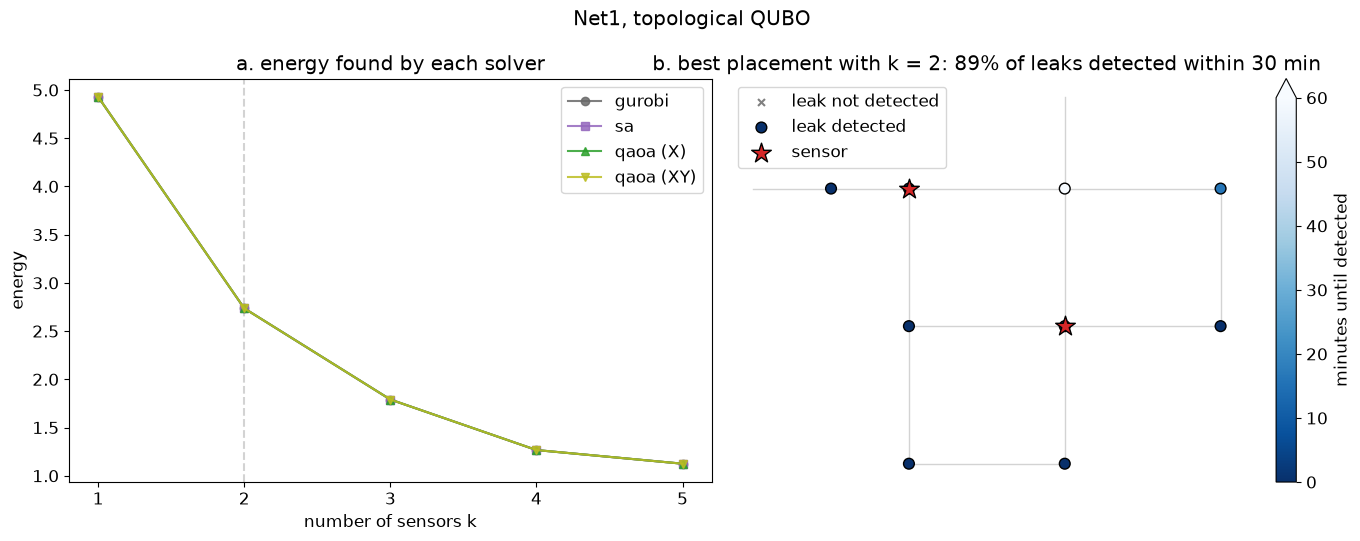

In [102]:
qubo_figure("Net1", "topological", 2)

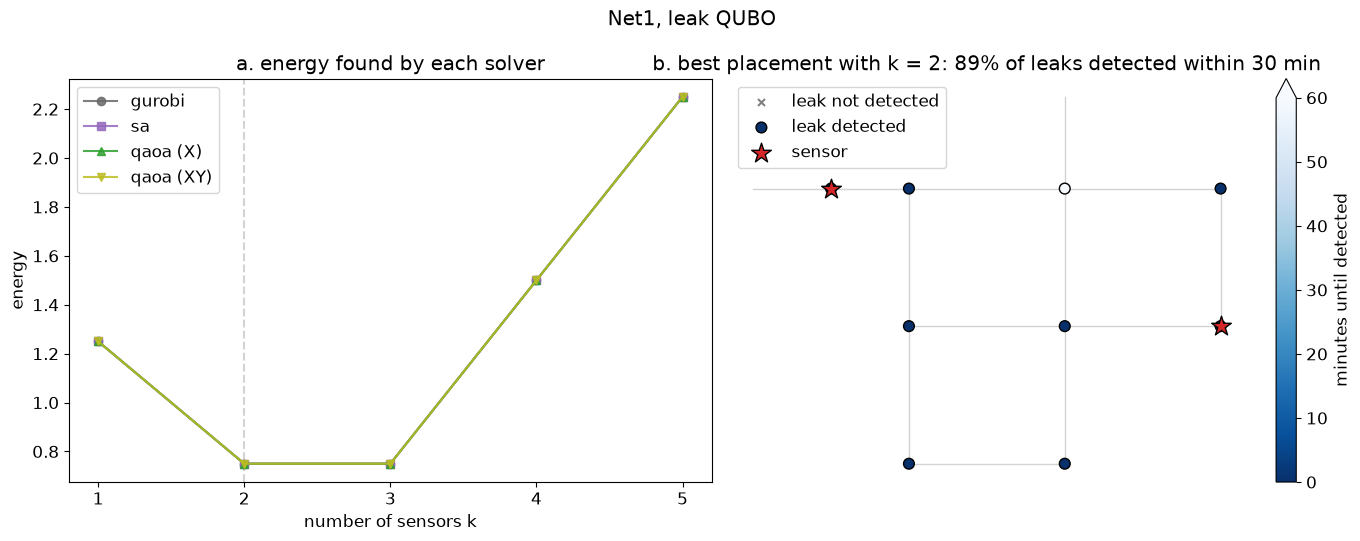

In [103]:
qubo_figure("Net1", "leak", 2)

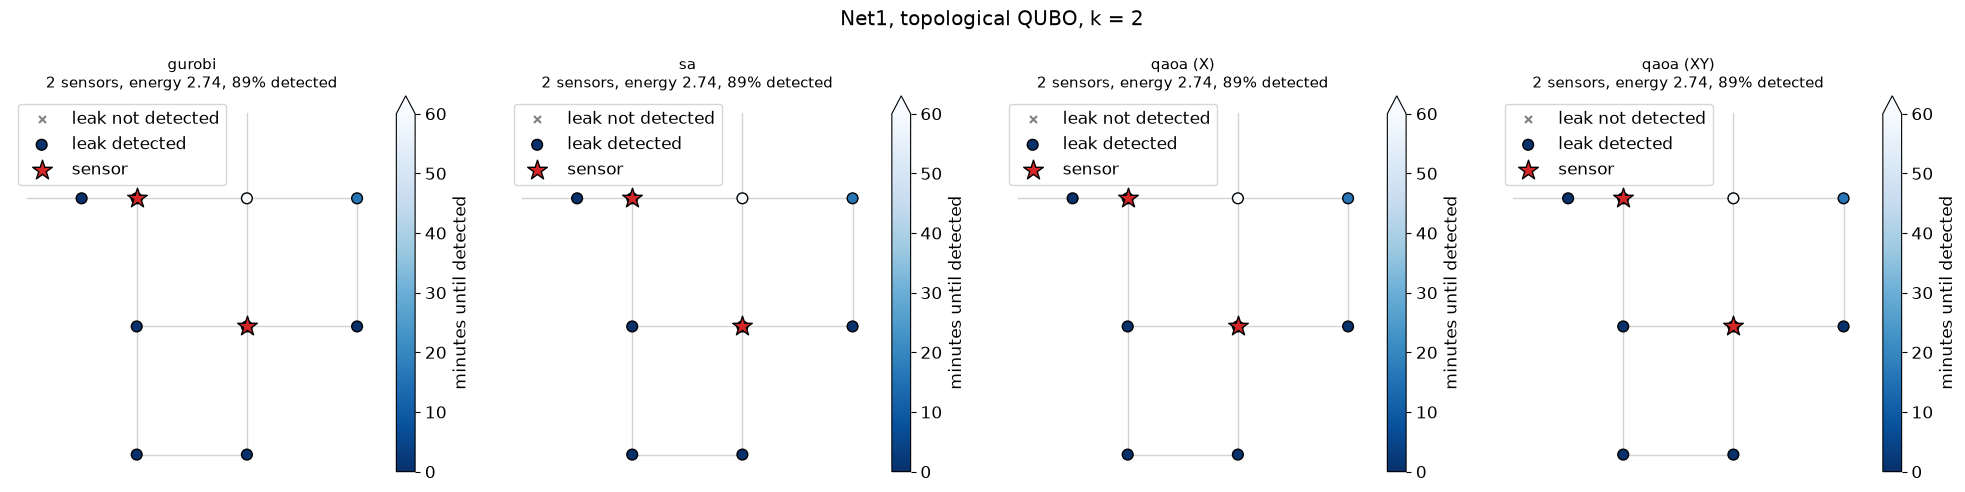

In [104]:
placement_figure("Net1", "topological", 2)

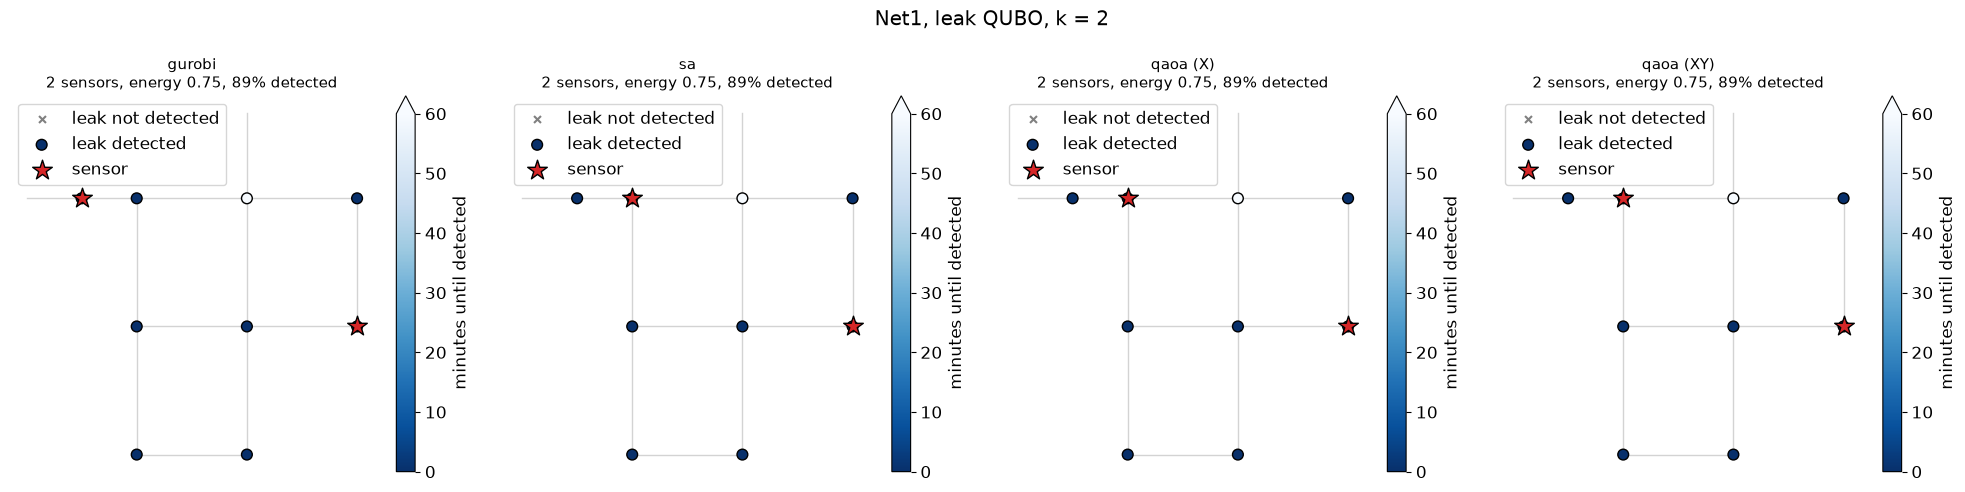

In [105]:
placement_figure("Net1", "leak", 2)

## 4. Energy for each number of sensors

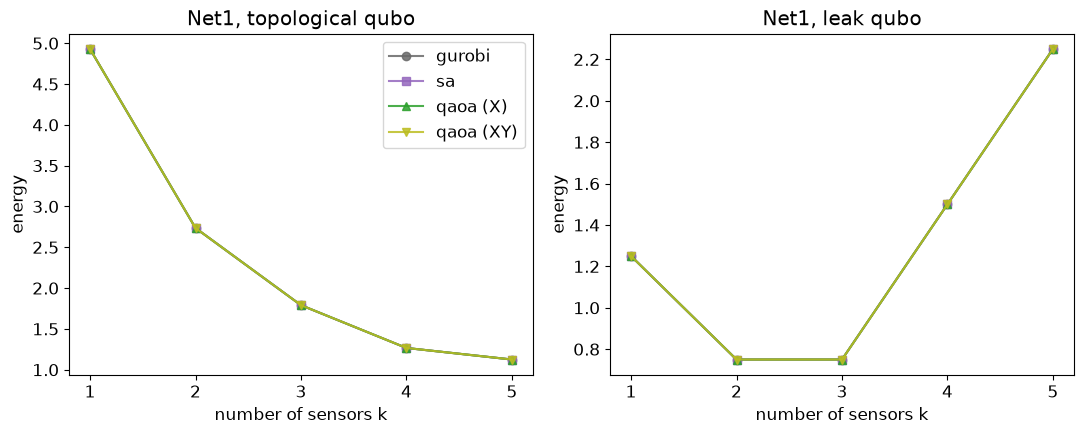

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, qubo in zip(axes, ["topological", "leak"]):
    for solver in solver_order:
        d = runs_all[(runs_all.formulation == qubo) & (runs_all.network == "Net1") & (runs_all.solver == solver)].sort_values("k")
        if len(d):
            ax.plot(d["k"], d["energy"], marker=markers[solver], color=solver_colors[solver], label=solver, alpha=0.85)
    ax.set_xticks(sorted(runs_all[runs_all.network == "Net1"]["k"].unique()))
    ax.set_title(f"Net1, {qubo} qubo")
    ax.set_xlabel("number of sensors k")
    ax.set_ylabel("energy")
axes[0].legend()
plt.tight_layout()
save_fig("energy_by_k_net1_xy.png")

## 5. Solve time

,variables,pair terms,gurobi time (s),sa time (s),qaoa (X) time (s),qaoa (XY) time (s)
Net1,9,36,0.009,0.015,42.378,6.126


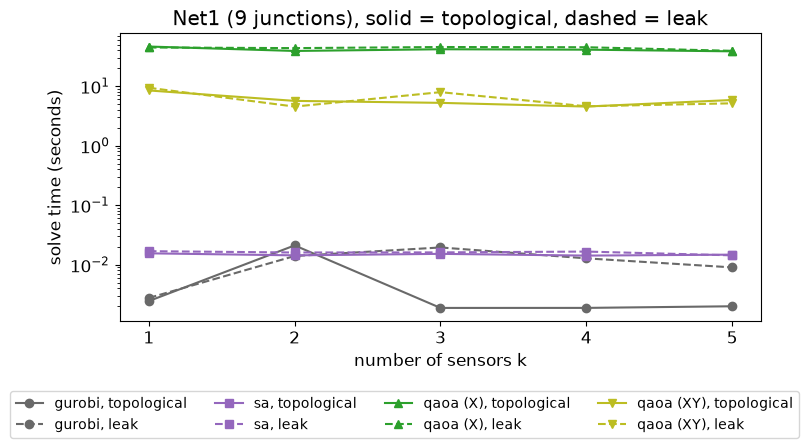

In [107]:
size = pd.DataFrame({"variables": [9], "pair terms": [9 * 8 // 2]}, index=["Net1"])
for solver in solver_order:
    size[f"{solver} time (s)"] = runs_all[(runs_all.solver == solver) & (runs_all.network == "Net1")]["runtime_s"].mean().round(3)
display(size)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
runs = runs_all[runs_all.network == "Net1"]
for solver in solver_order:
    for qubo, style in zip(["topological", "leak"], ["-", "--"]):
        d = runs[(runs.solver == solver) & (runs.formulation == qubo)].sort_values("k")
        if len(d):
            ax.plot(d["k"], d["runtime_s"], style, marker=markers[solver], color=solver_colors[solver],
                    label=f"{solver}, {qubo}")
ax.set_yscale("log")
ax.set_xticks(sorted(runs["k"].unique()))
ax.set_xlabel("number of sensors k")
ax.set_ylabel("solve time (seconds)")
ax.set_title("Net1 (9 junctions), solid = topological, dashed = leak")
fig.legend(fontsize=10, ncol=4, loc="lower center")
plt.tight_layout(rect=(0, 0.12, 1, 1))
save_fig("runtime_Net1_xy.png")

solver         qaoa (X)  qaoa (XY)  speedup (X / XY)
formulation k                                       
leak        1     44.57       9.38              4.75
            2     43.49       4.53              9.60
            3     45.38       7.91              5.73
            4     45.01       4.58              9.83
            5     39.16       5.14              7.62
topological 1     46.22       8.45              5.47
            2     38.97       5.65              6.90
            3     41.62       5.23              7.95
            4     40.95       4.53              9.03
            5     38.40       5.85              6.57

average speedup of XY over X:
formulation
leak           7.5
topological    7.2


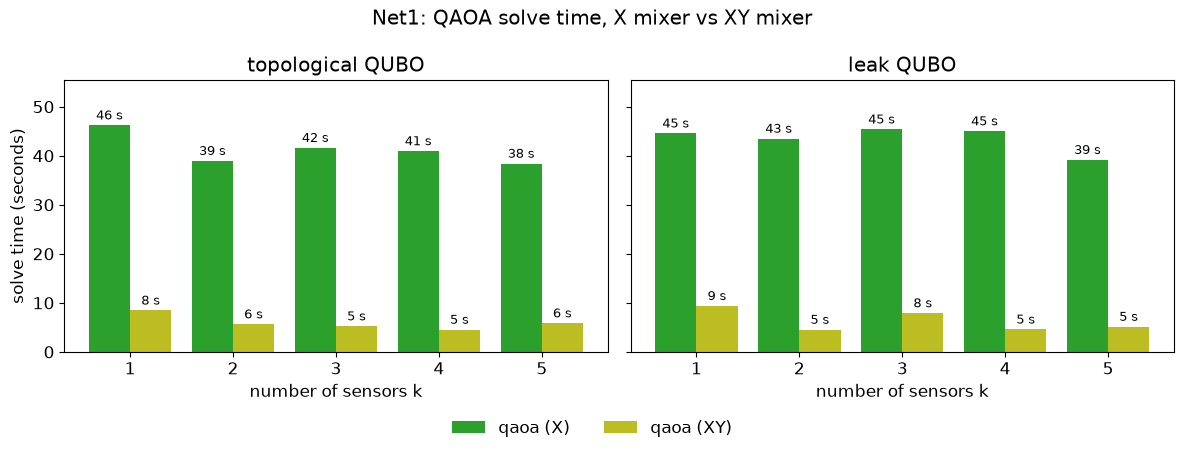

In [112]:
t = (runs_all[(runs_all.network == "Net1") & runs_all.solver.isin(["qaoa (X)", "qaoa (XY)"])]
     .pivot_table(index=["formulation", "k"], columns="solver", values="runtime_s"))
t["speedup (X / XY)"] = t["qaoa (X)"] / t["qaoa (XY)"]
display(t.round(2))
print("average speedup of XY over X:")
print(t.groupby("formulation")["speedup (X / XY)"].mean().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, qubo in zip(axes, ["topological", "leak"]):
    d = t.loc[qubo]
    x = np.arange(len(d.index))
    bx = ax.bar(x - 0.2, d["qaoa (X)"], width=0.4, color=solver_colors["qaoa (X)"], label="qaoa (X)")
    bxy = ax.bar(x + 0.2, d["qaoa (XY)"], width=0.4, color=solver_colors["qaoa (XY)"], label="qaoa (XY)")
    ax.bar_label(bx, fmt="%.0f s", padding=2, fontsize=9)
    ax.bar_label(bxy, fmt="%.0f s", padding=2, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(d.index)
    ax.set_xlabel("number of sensors k")
    ax.set_title(f"{qubo} QUBO")
    ax.set_ylim(0, 1.2 * t[["qaoa (X)", "qaoa (XY)"]].max().max())
axes[0].set_ylabel("solve time (seconds)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Net1: QAOA solve time, X mixer vs XY mixer")
plt.tight_layout(rect=(0, 0.07, 1, 1))
save_fig("runtime_x_vs_xy_net1.png")

## 6. One try

What is the chance that **one try** finds the optimum?
- **SA**: one run
- **QAOA (X) / QAOA (XY)**: one measurement
- **random guess (any)**: one of the 512 placements picked at random
- **random guess (k only)**: one placement with exactly k sensors picked at random. This is the search space the XY mixer works in, so it is the fair baseline for XY.

In [109]:
import itertools
from src.qubo import pick_penalty

builders = {"topological": build_Q_topological, "leak": build_Q_leak}
all_placements = list(itertools.product([0, 1], repeat=9))      # Net1 has 2^9 = 512 placements

# success % = share of a solver's measurements that reached the Gurobi optimum
runs_all["success %"] = [100 * success_rate(e, b) if len(e) else np.nan
                         for e, b in zip(runs_all.sample_energies, runs_all.best)]

rows = []
net1 = runs_all[runs_all.network == "Net1"]
for qubo in ["topological", "leak"]:
    for k in sorted(net1.k.unique()):
        Q0, const0, _ = builders[qubo]("Net1", k, penalty=0)
        Q, const, _ = builders[qubo]("Net1", k, pick_penalty(Q0))
        optimum = best_energy[("Net1", qubo, k)]

        # random guessing: how many placements are optimal
        optimal = [x for x in all_placements if abs(energy(Q, const, x) - optimum) < 1e-6]
        n_k = sum(sum(x) == k for x in all_placements)          # placements with exactly k sensors
        row = {"qubo": qubo, "k": k,
               "random guess (any)": 100 * len(optimal) / len(all_placements),
               "random guess (k only)": 100 * len(optimal) / n_k}
        for solver in ["sa", "qaoa (X)", "qaoa (XY)"]:
            run = net1[(net1.formulation == qubo) & (net1.k == k) & (net1.solver == solver)]
            row[solver] = run.iloc[0]["success %"] if len(run) else np.nan
        rows.append(row)

one_try = pd.DataFrame(rows).set_index(["qubo", "k"])[["sa", "qaoa (X)", "qaoa (XY)", "random guess (any)", "random guess (k only)"]]
one_try.round(1)

sa  qaoa (X)  qaoa (XY)  random guess (any)  \
qubo        k                                                  
topological 1  45.0       4.5       19.7                 0.2   
            2  46.0       1.6        5.9                 0.2   
            3  19.0       0.6        0.2                 0.2   
            4   8.0       0.4        0.6                 0.2   
            5   5.0       0.2        5.7                 0.2   
leak        1  26.0       3.9       15.6                 0.2   
            2  18.0       2.7        9.0                 0.4   
            3  22.0       2.0        4.5                 0.4   
            4  50.0       1.2        1.2                 1.4   
            5  82.0       0.8        0.8                 0.6   

               random guess (k only)  
qubo        k                         
topological 1                   11.1  
            2                    2.8  
            3                    1.2  
            4                    0.8  
            5                    0.8  
leak        1                   11.1  
            2                    5.6  
            3                    2.4  
            4                    5.6  
            5                    2.4

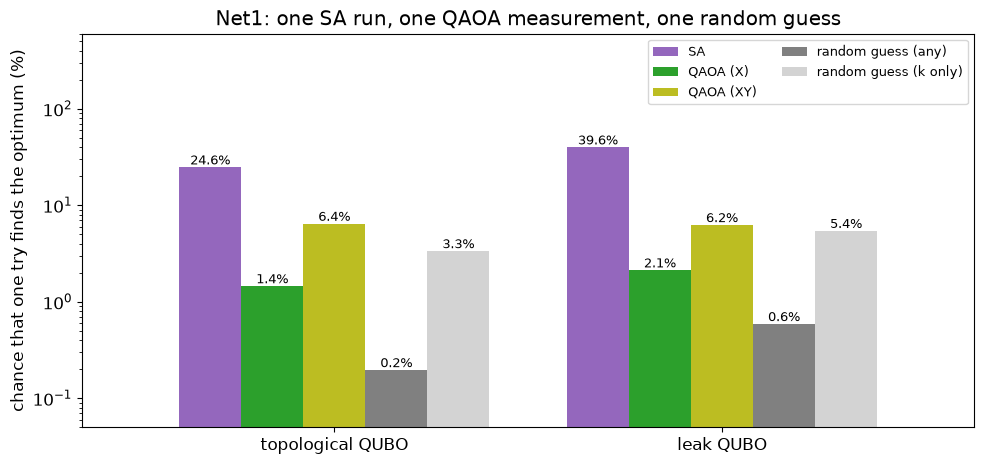

In [110]:
average = one_try.groupby("qubo").mean().loc[["topological", "leak"]]

ax = average.plot.bar(figsize=(10, 4.8), rot=0, width=0.8,
                      color=[solver_colors["sa"], solver_colors["qaoa (X)"], solver_colors["qaoa (XY)"], "gray", "lightgray"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", fontsize=9)
ax.set_yscale("log")
ax.set_ylim(0.05, 600)
ax.set_xticklabels([f"{q} QUBO" for q in average.index])
ax.set_xlabel("")
ax.set_ylabel("chance that one try finds the optimum (%)")
ax.set_title("Net1: one SA run, one QAOA measurement, one random guess")
ax.legend(["SA", "QAOA (X)", "QAOA (XY)", "random guess (any)", "random guess (k only)"], fontsize=9, ncol=2)
plt.tight_layout()
save_fig("one_try_net1_xy.png")

## 7. Does each mixer return exactly k sensors, and how good is a typical measurement?

The XY mixer keeps every measurement at exactly k sensors by construction. The X mixer relies on the penalty in the QUBO.

exactly k sensors (%)  average energy gap
qubo        solver                                              
leak        qaoa (X)                   40.94               12.40
            qaoa (XY)                 100.00                4.62
topological qaoa (X)                   37.54                4.68
            qaoa (XY)                 100.00                1.44

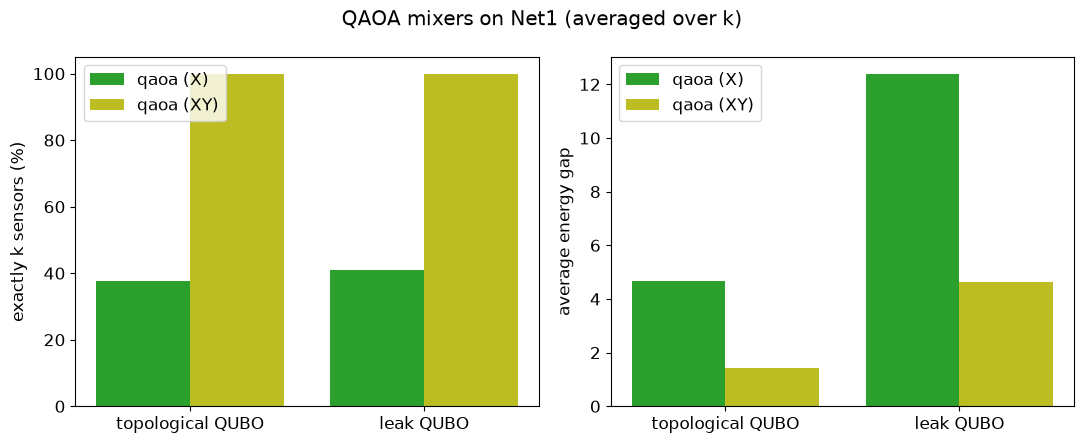

In [111]:
rows = []
for run in net1[net1.solver.isin(["qaoa (X)", "qaoa (XY)"])].itertuples():
    energies = np.array(run.sample_energies)
    rows.append({"qubo": run.formulation, "solver": run.solver, "k": run.k,
                 "exactly k sensors (%)": 100 * np.mean([len(s) == run.k for s in run.samples]),
                 "average energy gap": energies.mean() - run.best})
mixers = pd.DataFrame(rows)
summary = mixers.groupby(["qubo", "solver"])[["exactly k sensors (%)", "average energy gap"]].mean().round(2)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col in zip(axes, ["exactly k sensors (%)", "average energy gap"]):
    values = summary[col].unstack()[["qaoa (X)", "qaoa (XY)"]].loc[["topological", "leak"]]
    x = np.arange(len(values.index))
    for i, solver in enumerate(values.columns):
        bars = ax.bar(x + (i - 0.5) * 0.4, values[solver], width=0.4, color=solver_colors[solver], label=solver)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{q} QUBO" for q in values.index])
    ax.set_ylabel(col)
axes[0].legend(loc="upper left")
axes[1].legend()
fig.suptitle("QAOA mixers on Net1 (averaged over k)")
plt.tight_layout()
save_fig("mixer_feasibility_net1_xy.png")